<a href="https://colab.research.google.com/github/mehakgupta0406/marketing-ab-test-analysis/blob/main/Marketing_ab_testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business question
Does the conversion rate differ between users shown a marketing
advertisement and users shown a public service announcement (PSA)?

## Groups
- Ad group: users shown the marketing advertisement.
- PSA group: users shown a public service announcement.

## Primary metric
Conversion rate = number of converted users / total users in each group.

## Hypotheses
- Null hypothesis (H₀): The groups have equal conversion rates.
- Alternative hypothesis (H₁): The groups have different conversion rates.

## Statistical testing plan
- Use a two-sided two-proportion z-test to compare conversion rates.
- Use a significance level of 5% (α = 0.05).
- Calculate a 95% confidence interval for the difference
  in conversion rates (ad minus PSA).
- Assess statistical evidence alongside effect size and
  experiment limitations before drawing a business conclusion.

In [1]:
import pandas as pd

In [2]:
df=pd.read_csv("marketing_AB.csv")

In [3]:
df.shape

(588101, 7)

In [4]:
df.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Unnamed: 0     588101 non-null  int64 
 1   user id        588101 non-null  int64 
 2   test group     588101 non-null  object
 3   converted      588101 non-null  bool  
 4   total ads      588101 non-null  int64 
 5   most ads day   588101 non-null  object
 6   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(4), object(2)
memory usage: 27.5+ MB


In [6]:
df.drop("Unnamed: 0",axis=1,inplace=True)

In [7]:
df.shape

(588101, 6)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   user id        588101 non-null  int64 
 1   test group     588101 non-null  object
 2   converted      588101 non-null  bool  
 3   total ads      588101 non-null  int64 
 4   most ads day   588101 non-null  object
 5   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(3), object(2)
memory usage: 23.0+ MB


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   user id        588101 non-null  int64 
 1   test group     588101 non-null  object
 2   converted      588101 non-null  bool  
 3   total ads      588101 non-null  int64 
 4   most ads day   588101 non-null  object
 5   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(3), object(2)
memory usage: 23.0+ MB


In [12]:
df["user id"].duplicated().sum()

np.int64(0)

In [13]:
df['test group'].unique()

array(['ad', 'psa'], dtype=object)

In [14]:
import sqlite3

In [15]:
conn = sqlite3.connect(":memory:")

In [16]:
df.to_sql("marketing_ab", conn, index=False, if_exists="replace")

588101

In [17]:
query="""
Select "test group" as test_group, Count(*) as no_of_users from marketing_ab group by "test group" """

In [18]:
pd.read_sql_query(query, conn)

,test_group,no_of_users
0,ad,564577
1,psa,23524


In [19]:
query="""
Select "test group" as test_group, Count(*) as no_of_users , SUM(converted) as conversion from marketing_ab group by "test group" """

In [20]:
pd.read_sql_query(query, conn)

,test_group,no_of_users,conversion
0,ad,564577,14423
1,psa,23524,420


In [21]:
query="""
Select "test group" as test_group, Count(*) as no_of_users , SUM(converted) as conversion ,100.0*(SUM(converted))/Count(*) as conversion_rate from marketing_ab group by "test group" """

In [22]:
pd.read_sql_query(query, conn)

,test_group,no_of_users,conversion,conversion_rate
0,ad,564577,14423,2.554656
1,psa,23524,420,1.785411


In [23]:
result=pd.read_sql_query(query, conn).set_index("test_group")

In [24]:
absolutelift=(result.loc["ad","conversion_rate"]-result.loc["psa","conversion_rate"])

In [25]:
print(f"{absolutelift:.2f} absolute lift")

0.77 absolute lift


In [26]:
relative_lift=absolutelift/result.loc["psa","conversion_rate"]*100

In [27]:
print(f"{relative_lift:.2f}%")

43.09%


In [28]:
from statsmodels.stats.proportion import proportions_ztest

conversions = result.loc[["ad", "psa"], "conversion"].to_numpy()
users = result.loc[["ad", "psa"], "no_of_users"].to_numpy()

z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=users,
    alternative="two-sided"
)

print(f"Z-statistic: {z_stat:.3f}")
print(f"P-value: {p_value:.4g}")

if p_value < 0.05:
    print("Reject H₀: evidence that the conversion rates differ.")
else:
    print("Fail to reject H₀: insufficient evidence that the rates differ.")

Z-statistic: 7.370
P-value: 1.705e-13
Reject H₀: evidence that the conversion rates differ.


The two-sided two-proportion z-test found evidence of a
difference in conversion rates (z = 7.370, p < 0.001).

The ad group converted at 2.55%, compared with 1.79% for
the PSA group—an observed increase of 0.77 percentage points.

This result is statistically significant. Causal interpretation
depends on valid experiment design, and profitability requires
cost and conversion-value information.

In [29]:
from statsmodels.stats.proportion import confint_proportions_2indep

ci_low, ci_high = confint_proportions_2indep(
    count1=int(conversions[0]),
    nobs1=int(users[0]),
    count2=int(conversions[1]),
    nobs2=int(users[1]),
    compare="diff",
    method="newcomb",
    alpha=0.05
)

difference = conversions[0] / users[0] - conversions[1] / users[1]

print(f"Observed difference: {difference * 100:.3f} percentage points")
print(
    f"95% confidence interval: "
    f"{ci_low * 100:.3f} to {ci_high * 100:.3f} percentage points"
)

Observed difference: 0.769 percentage points
95% confidence interval: 0.587 to 0.936 percentage points


The ad group's conversion rate was 0.769 percentage points
higher than the PSA group's rate (95% confidence interval:
0.587 to 0.936 percentage points).

The interval excludes zero, consistent with the hypothesis
test's evidence of a difference between the groups.

In [30]:
import matplotlib.pyplot as plt

In [31]:
ad_rate = result.loc["ad", "conversion_rate"]
psa_rate = result.loc["psa", "conversion_rate"]

print(ad_rate)
print(psa_rate)

2.5546559636683748
1.7854106444482232


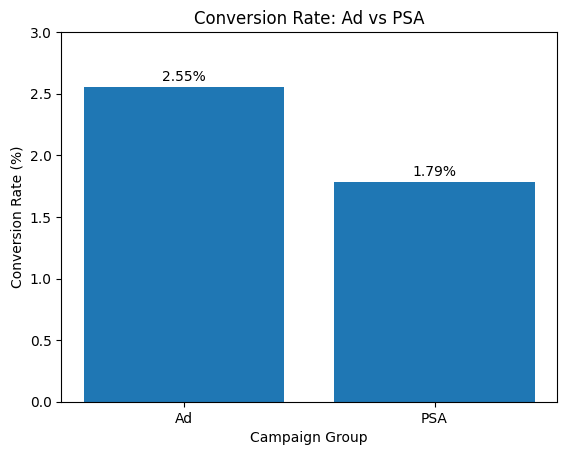

In [32]:
plt.bar(["Ad", "PSA"], [ad_rate, psa_rate])
plt.title("Conversion Rate: Ad vs PSA")
plt.xlabel("Campaign Group")
plt.ylabel("Conversion Rate (%)")
plt.text(0, ad_rate + 0.05, f"{ad_rate:.2f}%", ha="center")
plt.text(1, psa_rate + 0.05, f"{psa_rate:.2f}%", ha="center")
plt.ylim(0, 3)
plt.savefig("conversion_rates.png", dpi=300, bbox_inches="tight")
plt.show()

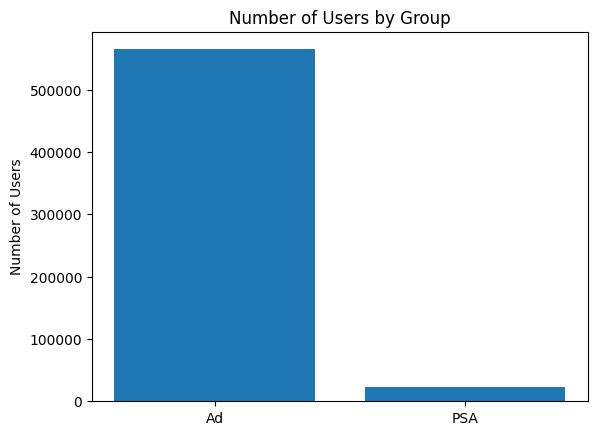

In [33]:
plt.bar(["Ad", "PSA"], users)

plt.title("Number of Users by Group")
plt.ylabel("Number of Users")

plt.show()

The ad group contains 564,577 users (96%), while the PSA
group contains 23,524 users (4%).

The intended allocation is unavailable, so we cannot confirm
whether this split matches the experiment design.

In [34]:
from google.colab import files

files.download("conversion_rates.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Business conclusion

The ad group had a conversion rate of 2.55%, compared with
1.79% for the PSA group.

The estimated increase was 0.769 percentage points
(95% confidence interval: 0.587–0.936), with a relative lift
of 43.09%. The difference was statistically significant
(p < 0.001).

These findings support further evaluation of the advertising
campaign. Before increasing spending, confirm the validity
of group assignment and compare campaign costs with the
value of additional conversions.

## Limitations

- Random assignment cannot be independently verified from
  the dataset alone, limiting causal conclusions.
- The groups have unequal sizes. The intended allocation
  is needed to check whether this was expected.
- Campaign costs and conversion values are unavailable,
  so profitability cannot be assessed.
- Results from this dataset may not generalize to other
  campaigns or audiences.

In [35]:
import pandas
import matplotlib
import statsmodels

print("pandas:", pandas.__version__)
print("matplotlib:", matplotlib.__version__)
print("statsmodels:", statsmodels.__version__)

pandas: 2.2.3
matplotlib: 3.10.0
statsmodels: 0.15.0


In [36]:
day_query="""
Select "most ads day" as day ,"test group" as test_group, Count(*) as no_of_users , SUM(converted) as conversion ,100.0*(SUM(converted))/Count(*) as conversion_rate from marketing_ab group by "most ads day", "test group" """

In [37]:
day_result = pd.read_sql_query(day_query, conn)

In [38]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

In [39]:
print("Day and group summary:")
print(
    day_result.set_index(["day", "test_group"])
    .reindex(day_order, level="day")
    .round(2)
)

Day and group summary:
                      no_of_users  conversion  conversion_rate
day       test_group                                          
Monday    ad                83571        2778             3.32
          psa                3502          79             2.26
Tuesday   ad                74572        2270             3.04
          psa                2907          42             1.44
Wednesday ad                77418        1963             2.54
          psa                3490          55             1.58
Thursday  ad                79077        1711             2.16
          psa                3905          79             2.02
Friday    ad                88805        1995             2.25
          psa                3803          62             1.63
Saturday  ad                78802        1679             2.13
          psa                2858          40             1.40
Sunday    ad                82332        2027             2.46
          psa                305

In [40]:
day_comparison = day_result.pivot(
    index="day",
    columns="test_group",
    values="conversion_rate"
).reindex(day_order)

In [41]:
day_comparison

test_group,ad,psa
day,,
Monday,3.324120,2.255854
Tuesday,3.044038,1.444788
Wednesday,2.535586,1.575931
Thursday,2.163714,2.023047
Friday,2.246495,1.630292
Saturday,2.130657,1.399580
Sunday,2.461983,2.059497


In [42]:
day_comparison["difference_pp"] = (
    day_comparison["ad"] - day_comparison["psa"]
)

In [43]:
day_comparison["difference_pp"]

,difference_pp
day,
Monday,1.068266
Tuesday,1.599250
Wednesday,0.959655
Thursday,0.140666
Friday,0.616203
Saturday,0.731076
Sunday,0.402487


In [44]:
psa_baseline = day_comparison["psa"].replace(0, float("nan"))

In [45]:
day_comparison["relative_lift_pct"] = (
    (day_comparison["ad"] - day_comparison["psa"])
    / psa_baseline
) * 100

In [46]:
print("\nConversion rates and lift by day:")
print(day_comparison.round(2))


Conversion rates and lift by day:
test_group    ad   psa  difference_pp  relative_lift_pct
day                                                     
Monday      3.32  2.26           1.07              47.36
Tuesday     3.04  1.44           1.60             110.69
Wednesday   2.54  1.58           0.96              60.89
Thursday    2.16  2.02           0.14               6.95
Friday      2.25  1.63           0.62              37.80
Saturday    2.13  1.40           0.73              52.24
Sunday      2.46  2.06           0.40              19.54


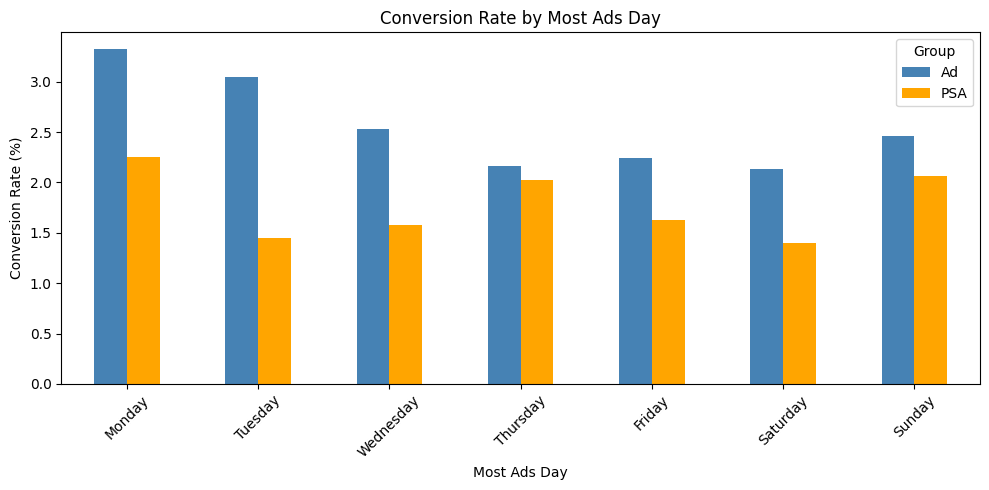

In [47]:
ax = day_comparison[["ad", "psa"]].plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "orange"]
)
ax.set_title("Conversion Rate by Most Ads Day")
ax.set_xlabel("Most Ads Day")
ax.set_ylabel("Conversion Rate (%)")
ax.legend(["Ad", "PSA"], title="Group")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [48]:
hour_query = """
SELECT
    "most ads hour" AS hour,
    "test group" AS test_group,
    COUNT(*) AS users,
    SUM(converted) AS conversions,
    100.0 * SUM(converted) / COUNT(*) AS conversion_rate
FROM marketing_ab
GROUP BY "most ads hour", "test group"
ORDER BY hour, test_group
"""

In [49]:
hour_result = pd.read_sql_query(hour_query, conn)

display(hour_result.round(2))


,hour,test_group,users,conversions,conversion_rate
0,0,ad,5309,102,1.92
1,0,psa,227,0,0.00
2,1,ad,4615,62,1.34
3,1,psa,187,0,0.00
4,2,ad,5152,39,0.76
5,2,psa,181,0,0.00
6,3,ad,2590,27,1.04
7,3,psa,89,1,1.12
8,4,ad,694,11,1.59
9,4,psa,28,0,0.00


In [50]:
hour_comparison = hour_result.pivot(
    index="hour",
    columns="test_group",
    values="conversion_rate"
).reindex(range(24))

In [51]:
hour_comparison

test_group,ad,psa
hour,,
0,1.921266,0.000000
1,1.343445,0.000000
2,0.756988,0.000000
3,1.042471,1.123596
4,1.585014,0.000000
5,2.156334,0.000000
6,2.317380,0.000000
7,1.848249,0.843882
8,1.986091,1.062215


In [52]:
hour_comparison["difference_pp"] = (
    hour_comparison["ad"] - hour_comparison["psa"]
)

In [53]:
psa_baseline = hour_comparison["psa"].replace(0, float("nan"))

In [54]:
hour_comparison["relative_lift_pct"] = (
    (hour_comparison["ad"] - hour_comparison["psa"])
    / psa_baseline
) * 100

In [55]:
display(hour_comparison.round(2))

test_group,ad,psa,difference_pp,relative_lift_pct
hour,,,,
0,1.92,0.00,1.92,NaN
1,1.34,0.00,1.34,NaN
2,0.76,0.00,0.76,NaN
3,1.04,1.12,-0.08,-7.22
4,1.59,0.00,1.59,NaN
5,2.16,0.00,2.16,NaN
6,2.32,0.00,2.32,NaN
7,1.85,0.84,1.00,119.02
8,1.99,1.06,0.92,86.98


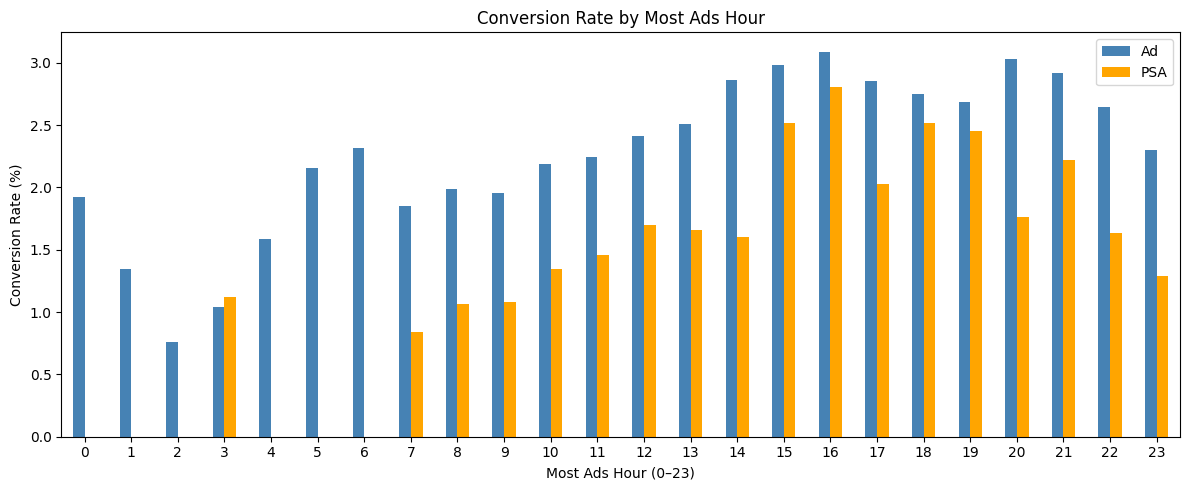

In [56]:
ax = hour_comparison[["ad", "psa"]].plot(
    kind="bar",
    figsize=(12, 5),
    color=["steelblue", "orange"]
)
ax.set_title("Conversion Rate by Most Ads Hour")
ax.set_xlabel("Most Ads Hour (0–23)")
ax.set_ylabel("Conversion Rate (%)")
ax.legend(["Ad", "PSA"])

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [57]:
exposure_cutoff = df["total ads"].median()

print(f"Exposure cutoff: {exposure_cutoff:g} ads")

Exposure cutoff: 13 ads


In [58]:
exposure_query = """
SELECT
    CASE
        WHEN "total ads" <= ? THEN 'Light'
        ELSE 'Heavy'
    END AS exposure,
    "test group" AS test_group,
    COUNT(*) AS users,
    SUM(converted) AS conversions,
    100.0 * SUM(converted) / COUNT(*) AS conversion_rate
FROM marketing_ab
GROUP BY exposure, "test group"
"""

In [59]:
exposure_result = pd.read_sql_query(
    exposure_query,
    conn,
    params=(float(exposure_cutoff),)
)

In [60]:
display(exposure_result.round(2))

,exposure,test_group,users,conversions,conversion_rate
0,Heavy,ad,277682,13344,4.81
1,Heavy,psa,10923,369,3.38
2,Light,ad,286895,1079,0.38
3,Light,psa,12601,51,0.40


In [61]:
exposure_comparison = exposure_result.pivot(
    index="exposure",
    columns="test_group",
    values="conversion_rate"
).reindex(["Light", "Heavy"])

In [62]:
exposure_comparison["difference_pp"] = (
    exposure_comparison["ad"] - exposure_comparison["psa"]
)

In [63]:
psa_baseline = exposure_comparison["psa"].replace(
    0, float("nan")
)

exposure_comparison["relative_lift_pct"] = (
    (exposure_comparison["ad"] - exposure_comparison["psa"])
    / psa_baseline
) * 100

In [64]:
display(exposure_comparison.round(2))


test_group,ad,psa,difference_pp,relative_lift_pct
exposure,,,,
Light,0.38,0.40,-0.03,-7.07
Heavy,4.81,3.38,1.43,42.25


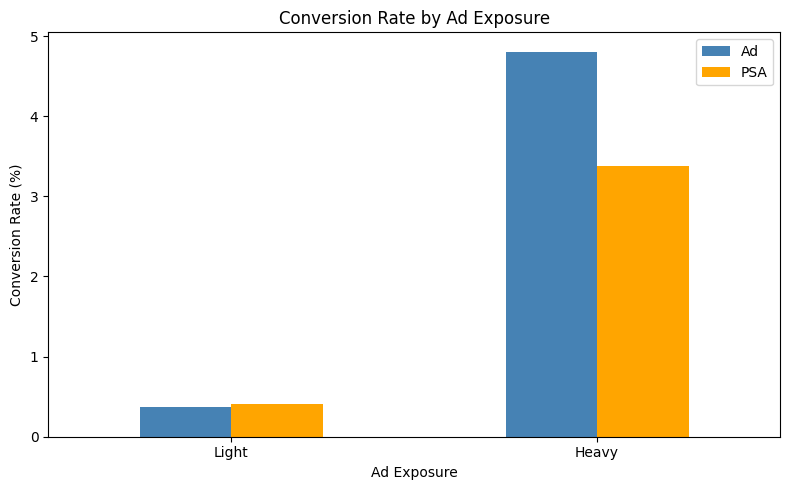

In [65]:
ax = exposure_comparison[["ad", "psa"]].plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "orange"]
)

ax.set_title("Conversion Rate by Ad Exposure")
ax.set_xlabel("Ad Exposure")
ax.set_ylabel("Conversion Rate (%)")
ax.legend(["Ad", "PSA"])

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [66]:
print("Conversion by day:")
display(day_comparison.round(2))



Conversion by day:


test_group,ad,psa,difference_pp,relative_lift_pct
day,,,,
Monday,3.32,2.26,1.07,47.36
Tuesday,3.04,1.44,1.60,110.69
Wednesday,2.54,1.58,0.96,60.89
Thursday,2.16,2.02,0.14,6.95
Friday,2.25,1.63,0.62,37.80
Saturday,2.13,1.40,0.73,52.24
Sunday,2.46,2.06,0.40,19.54


In [67]:

print("Conversion by hour:")
display(hour_comparison.round(2))

Conversion by hour:


test_group,ad,psa,difference_pp,relative_lift_pct
hour,,,,
0,1.92,0.00,1.92,NaN
1,1.34,0.00,1.34,NaN
2,0.76,0.00,0.76,NaN
3,1.04,1.12,-0.08,-7.22
4,1.59,0.00,1.59,NaN
5,2.16,0.00,2.16,NaN
6,2.32,0.00,2.32,NaN
7,1.85,0.84,1.00,119.02
8,1.99,1.06,0.92,86.98


In [68]:

print("Conversion by ad exposure:")
display(exposure_comparison.round(2))

Conversion by ad exposure:


test_group,ad,psa,difference_pp,relative_lift_pct
exposure,,,,
Light,0.38,0.40,-0.03,-7.07
Heavy,4.81,3.38,1.43,42.25


Conversion by most ads day: Users whose highest ad activity occurred on Monday had the highest observed Ad conversion rate (3.32%). Tuesday showed the largest observed Ad–PSA difference (1.60 percentage points; 110.69% relative lift), while Thursday showed the smallest (0.14 percentage points). Ad conversion rates exceeded PSA rates across all days. These comparisons are exploratory; statistical significance has not been tested within each segment.

Conversion by most ads hour: Users whose highest ad activity occurred at 16:00 had the highest observed Ad conversion rate (3.09%). The largest defined relative lift occurred at 07:00 (119.02%). Ad conversion rates exceeded PSA rates at all hours except 03:00. Relative lift was undefined for hours with zero PSA conversions.

Conversion by ad exposure: In the Heavy exposure segment, Ad users converted at 4.81%, compared with 3.38% for PSA—a difference of 1.43 percentage points and relative lift of 42.25%. In the Light segment, Ad users had a slightly lower conversion rate than PSA users, with relative lift of −7.07%.

Interpretation: These comparisons are exploratory, and significance has not been tested within segments. Exposure, day, and hour describe observed ad activity; these results do not establish that increasing exposure or changing ad timing causes higher conversion.